# Illumination analysis: when the docking port is in the light

The closed-loop simulation gave the relative sensor a target it could always see. A real optical sensor needs light. A camera that looks at a pattern on the docking port of the chief works only if the Sun illuminates the port, from a direction that does not leave it in deep shadow, and only if the Sun itself is not in the field of view. For a third of every orbit there is no Sun at all, because the chief is in the shadow of the Earth. The same geometry decides the electrical power and the temperatures of both spacecraft, but for the approach its most direct consequence is on timing: the final approach lasts a few minutes, and those minutes have to fall inside a window in which the port is lit.

This notebook builds the analysis from the bottom. It computes the direction of the Sun and checks it against known astronomical events, defines the beta angle and the eclipses that depend on it, follows them over a year, derives the lighting of the port in the frame of the chief, and finally adds a go/no-go on lighting to the simulation, so that the deputy waits at the last hold point until the light is right.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

import copy
from datetime import datetime, timedelta

from ios_mission_planner.constants import J2_EARTH, MU_EARTH, R_EARTH
from ios_mission_planner.dynamics.orbital.perturbations import j2_secular_rates
from ios_mission_planner.gnc.mission_manager import Phase
from ios_mission_planner.illumination.eclipse import critical_beta, eclipse_fraction_circular, in_eclipse
from ios_mission_planner.illumination.lighting import beta_angle_history, port_lighting_timeline
from ios_mission_planner.illumination.sun import (
    AU_KM, julian_date, julian_date_from_datetime, sun_direction, sun_position,
)
from ios_mission_planner.sim.config import SimulationConfig
from ios_mission_planner.sim.simulator import simulate

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"
COL_ZONE = "#9467bd"

COL_LIGHT = "#2ca02c"

RADIUS = R_EARTH + 500.0
INCLINATION = np.deg2rad(51.6)
RAAN = np.deg2rad(40.0)
PERIOD = 2 * np.pi * np.sqrt(RADIUS**3 / MU_EARTH)

## Where the Sun is

`sun_position` implements the low-precision series of the Astronomical Almanac: the mean longitude and the mean anomaly of the Sun grow linearly with time, the equation of the center adds the effect of the eccentricity of the orbit of the Earth, and a rotation by the obliquity of the ecliptic takes the result to the equatorial frame. Its accuracy, about a hundredth of a degree, is far better than a lighting analysis needs.

It can be checked without any other software. At an equinox the Sun crosses the equator, so its declination is zero and its right ascension is 0 or 180 degrees; at a solstice the declination reaches plus or minus the obliquity, 23.44 degrees, at a right ascension of 90 or 270 degrees. The instants of these events in 2026 are published, and so are the dates and distances of perihelion and aphelion.

event (UTC)                            declination   right ascension
March equinox      2026-03-20 14:46      +0.0020 deg      0.0045 deg
June solstice      2026-06-21 08:25     +23.4358 deg     90.0004 deg
September equinox  2026-09-23 00:05      +0.0031 deg    179.9929 deg
December solstice  2026-12-21 20:50     -23.4358 deg    269.9968 deg

perihelion: day 4 of the year, 0.98329 AU
aphelion:   day 186 of the year, 1.01671 AU


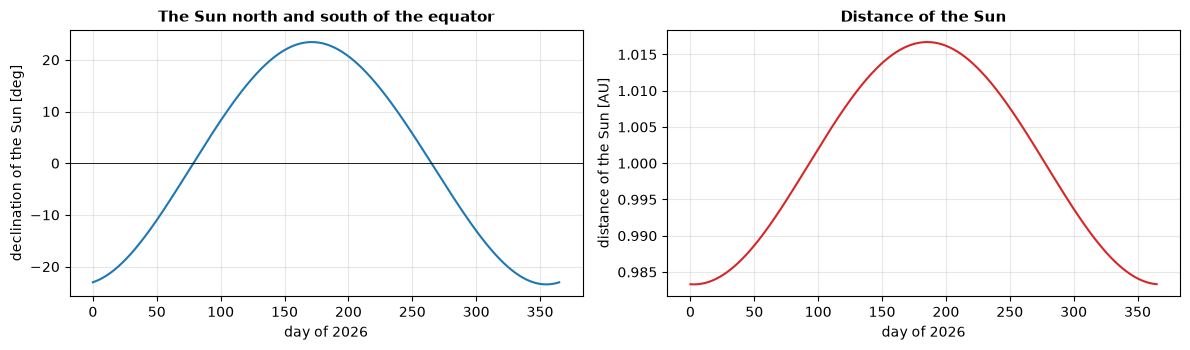

In [2]:
events = {
    "March equinox      2026-03-20 14:46": (2026, 3, 20, 14, 46),
    "June solstice      2026-06-21 08:25": (2026, 6, 21, 8, 25),
    "September equinox  2026-09-23 00:05": (2026, 9, 23, 0, 5),
    "December solstice  2026-12-21 20:50": (2026, 12, 21, 20, 50),
}
print(f"{'event (UTC)':38s} declination   right ascension")
for name, instant in events.items():
    s = sun_direction(julian_date(*instant))
    print(f"{name:38s} {np.degrees(np.arcsin(s[2])):+9.4f} deg   {np.degrees(np.arctan2(s[1], s[0])) % 360:9.4f} deg")

days = np.arange(0, 366)
jd = julian_date(2026, 1, 1) + days
position = sun_position(jd)
distance = np.linalg.norm(position, axis=1) / AU_KM
declination = np.degrees(np.arcsin(position[:, 2] / np.linalg.norm(position, axis=1)))
print(f"\nperihelion: day {distance.argmin() + 1} of the year, {distance.min():.5f} AU")
print(f"aphelion:   day {distance.argmax() + 1} of the year, {distance.max():.5f} AU")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(days, declination, color=COL_ANA)
axes[0].axhline(0, color="k", lw=0.6)
axes[0].set_xlabel("day of 2026"); axes[0].set_ylabel("declination of the Sun [deg]")
axes[0].set_title("The Sun north and south of the equator")
axes[1].plot(days, distance, color=COL_NUM)
axes[1].set_xlabel("day of 2026"); axes[1].set_ylabel("distance of the Sun [AU]")
axes[1].set_title("Distance of the Sun")
fig.tight_layout()

The four events are reproduced within 0.005 degrees in declination and 0.007 degrees in right ascension. The published instants are rounded to the minute, during which the Sun moves by less than a thousandth of a degree, so the residual is the accuracy of the series itself. The distance behaves as it should: the Earth is closest to the Sun in the first days of January, at 0.9833 AU, and farthest in the first days of July, at 1.0167 AU.

## Beta angle and eclipses

For an orbit, what matters is not where the Sun is in the sky but where it is with respect to the orbit plane. The beta angle is the angle between the direction of the Sun and the orbit plane. When it is zero the Sun lies in the plane: the spacecraft passes exactly behind the Earth and the eclipse is the longest possible. As the beta angle grows the orbit cuts the shadow along a shorter chord, and above a critical value it misses the shadow altogether.

With the shadow of the Earth taken as a cylinder of radius $R$, a circular orbit of radius $a$ spends in eclipse the fraction

$$
f = \frac{1}{\pi}\arccos\left(\frac{\sqrt{1 - (R/a)^2}}{\cos\beta}\right), \qquad |\beta| < \beta^* = \arcsin\frac{R}{a},
$$

and none above $\beta^*$. The plot compares this formula with a direct count of the points of the orbit that fall inside the shadow.

orbital period: 94.6 min
longest eclipse (beta = 0): 35.8 min, 37.8 % of the orbit
critical beta: 68.0 deg
largest difference between formula and count: 0.3 s


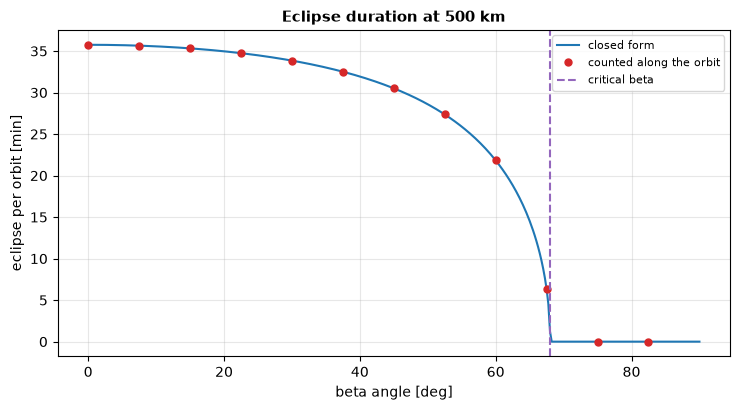

In [3]:
beta = np.radians(np.linspace(0, 90, 361))
fraction = eclipse_fraction_circular(RADIUS, beta, R_EARTH)

u = np.linspace(0, 2 * np.pi, 20001)
orbit = RADIUS * np.stack([np.cos(u), np.sin(u), np.zeros_like(u)], axis=-1)
checked = np.radians(np.arange(0, 90, 7.5))
counted = np.array([in_eclipse(orbit, np.array([np.cos(b), 0.0, np.sin(b)]), R_EARTH).mean() for b in checked])

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(np.degrees(beta), fraction * PERIOD / 60, color=COL_ANA, label="closed form")
ax.plot(np.degrees(checked), counted * PERIOD / 60, "o", color=COL_NUM, ms=5, label="counted along the orbit")
ax.axvline(np.degrees(critical_beta(RADIUS, R_EARTH)), color=COL_ZONE, ls="--", label="critical beta")
ax.set_xlabel("beta angle [deg]"); ax.set_ylabel("eclipse per orbit [min]")
ax.set_title("Eclipse duration at 500 km")
ax.legend(fontsize=8)
fig.tight_layout()

print(f"orbital period: {PERIOD / 60:.1f} min")
print(f"longest eclipse (beta = 0): {eclipse_fraction_circular(RADIUS, 0.0, R_EARTH) * PERIOD / 60:.1f} min, "
      f"{eclipse_fraction_circular(RADIUS, 0.0, R_EARTH) * 100:.1f} % of the orbit")
print(f"critical beta: {np.degrees(critical_beta(RADIUS, R_EARTH)):.1f} deg")
print(f"largest difference between formula and count: "
      f"{np.abs(eclipse_fraction_circular(RADIUS, checked, R_EARTH) - counted).max() * PERIOD:.1f} s")

The formula and the count agree within a fraction of a second. At 500 km the longest eclipse lasts 35.8 minutes, 38 percent of the orbit, and there is no eclipse above a beta angle of 68 degrees.

## The beta angle over a year

The beta angle changes for two reasons. The Sun moves along the ecliptic, once a year. And the orbit plane itself turns: the oblateness of the Earth makes the node regress, as the chapter on perturbations showed, by several degrees per day at this altitude and inclination. The second motion is much faster than the first, so the beta angle oscillates with a period of about two months, between limits set by the inclination of the orbit and the obliquity of the ecliptic.

nodal regression: -4.75 deg/day
beta between -74.9 and 73.4 deg (inclination + obliquity = 75.0 deg)
mean time between two passages through zero: 31.4 days
days of the year without eclipse: 15


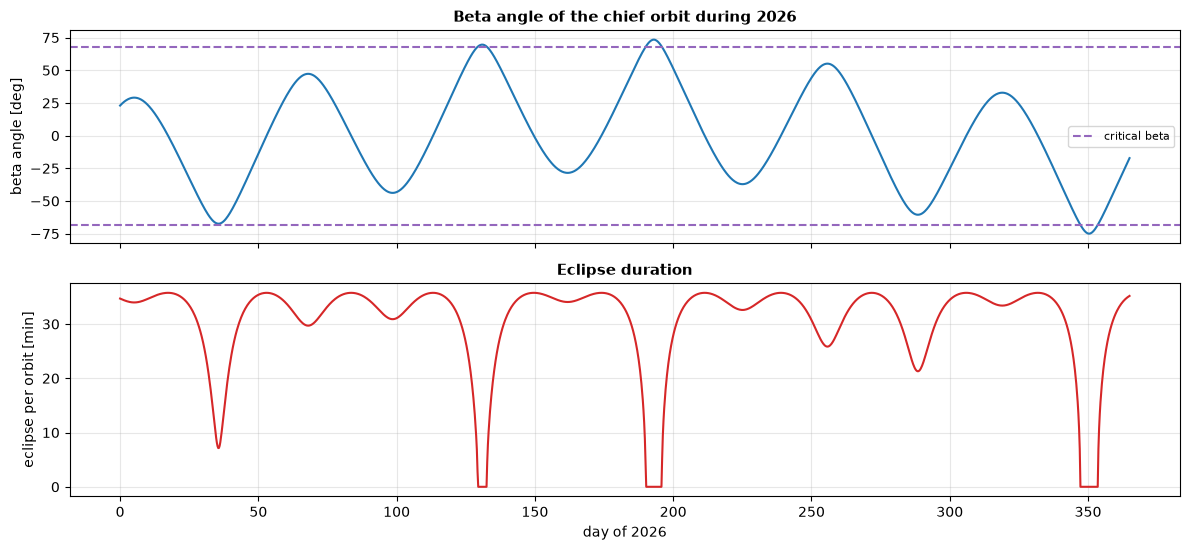

In [4]:
raan_rate, _, _ = j2_secular_rates(RADIUS, 0.0, INCLINATION, MU_EARTH, J2_EARTH, R_EARTH)
t_days, beta_year = beta_angle_history(RADIUS, INCLINATION, RAAN, julian_date(2026, 1, 1), 365.0,
                                       MU_EARTH, J2_EARTH, R_EARTH)
eclipse_minutes = eclipse_fraction_circular(RADIUS, beta_year, R_EARTH) * PERIOD / 60

fig, axes = plt.subplots(2, 1, figsize=(12, 5.6), sharex=True)
axes[0].plot(t_days, np.degrees(beta_year), color=COL_ANA)
limit = np.degrees(critical_beta(RADIUS, R_EARTH))
axes[0].axhline(limit, color=COL_ZONE, ls="--"); axes[0].axhline(-limit, color=COL_ZONE, ls="--", label="critical beta")
axes[0].set_ylabel("beta angle [deg]")
axes[0].set_title("Beta angle of the chief orbit during 2026")
axes[0].legend(fontsize=8)
axes[1].plot(t_days, eclipse_minutes, color=COL_NUM)
axes[1].set_xlabel("day of 2026"); axes[1].set_ylabel("eclipse per orbit [min]")
axes[1].set_title("Eclipse duration")
fig.tight_layout()

crossings = t_days[1:][np.diff(np.sign(beta_year)) != 0]
print(f"nodal regression: {np.degrees(raan_rate) * 86400:.2f} deg/day")
print(f"beta between {np.degrees(beta_year.min()):.1f} and {np.degrees(beta_year.max()):.1f} deg "
      f"(inclination + obliquity = {51.6 + 23.44:.1f} deg)")
print(f"mean time between two passages through zero: {np.diff(crossings).mean():.1f} days")
print(f"days of the year without eclipse: {(eclipse_minutes == 0).mean() * 365:.0f}")

The node regresses by 4.75 degrees per day, so the orbit plane goes around once in about 76 days, and the beta angle passes through zero every 31 days on average. It covers almost the whole range that geometry allows, plus or minus 75 degrees, the sum of the inclination and of the obliquity. For most of the year the chief has an eclipse of 30 to 36 minutes on every orbit. Around the peaks of the beta angle the eclipse shortens rapidly, and for about two weeks in the year it disappears.

## Lighting of the docking port

The port of the chief is fixed in the LVLH frame, and in that frame the Sun is not fixed: the frame turns once per orbit, so the Sun appears to turn once per orbit about the orbit normal, at a constant angle, the beta angle, from the orbit plane. `port_lighting_timeline` follows it and evaluates three conditions. The chief must be out of eclipse. The angle between the Sun and the outward normal of the port, the incidence, must be below a limit, here 70 degrees, because a grazing light leaves the target in long shadows. And the Sun must stay out of a cone around the optical axis of the camera of the deputy, which looks at the port from the opposite direction.

The timeline below starts at the epoch of the reference simulation and covers two orbits.

beta angle at the epoch: 30.3 deg
eclipse: 36 % of the orbit; favourable lighting: 26 %
  favourable from    0.0 to   23.1 min (23.1 min)
  favourable from   93.5 to  117.8 min (24.2 min)
  favourable from  188.2 to  189.2 min (1.1 min)


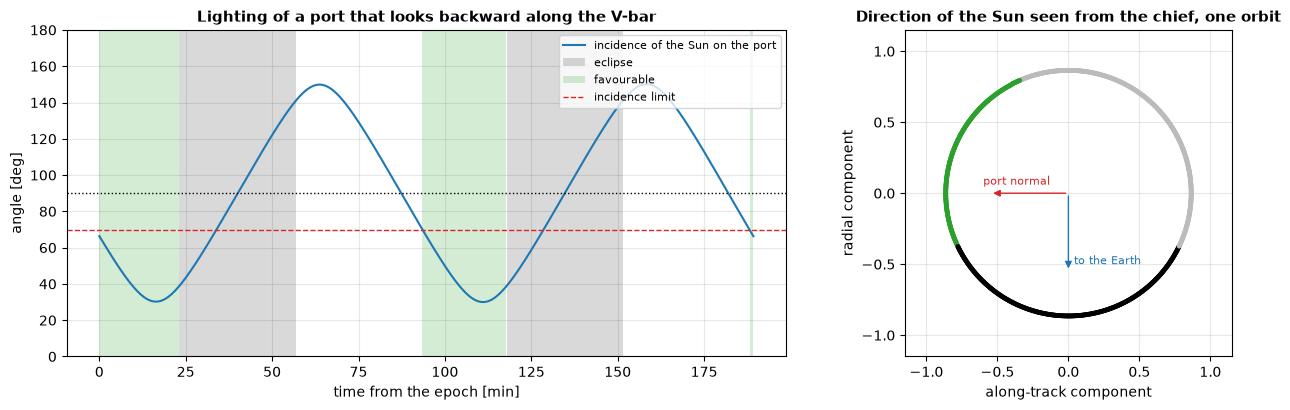

In [5]:
config = SimulationConfig()
epoch = julian_date_from_datetime(config.epoch)
timeline = port_lighting_timeline(RADIUS, INCLINATION, RAAN, np.deg2rad(config.chief.argument_of_latitude_deg),
                                  epoch, 2 * PERIOD, 5.0, MU_EARTH, J2_EARTH, R_EARTH,
                                  port_normal_lvlh=config.chief.port_axis)
minutes = timeline.t / 60

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.7, 1]})
ax = axes[0]
ax.plot(minutes, np.degrees(timeline.incidence), color=COL_ANA, label="incidence of the Sun on the port")
ax.fill_between(minutes, 0, 180, where=timeline.eclipse, color="k", alpha=0.15, lw=0, label="eclipse")
ax.fill_between(minutes, 0, 180, where=timeline.favourable, color=COL_LIGHT, alpha=0.2, lw=0, label="favourable")
ax.axhline(70, color=COL_NUM, ls="--", lw=1, label="incidence limit")
ax.axhline(90, color="k", ls=":", lw=1)
ax.set_ylim(0, 180)
ax.set_xlabel("time from the epoch [min]"); ax.set_ylabel("angle [deg]")
ax.set_title("Lighting of a port that looks backward along the V-bar")
ax.legend(fontsize=8, loc="upper right")

ax = axes[1]
one_orbit = timeline.t <= PERIOD
colors = np.where(timeline.eclipse, "k", np.where(timeline.favourable, COL_LIGHT, "#bbbbbb"))
ax.scatter(timeline.sun_lvlh[one_orbit, 1], timeline.sun_lvlh[one_orbit, 0], c=colors[one_orbit], s=6)
ax.annotate("", xy=(-0.55, 0), xytext=(0, 0), arrowprops={"arrowstyle": "-|>", "color": COL_NUM})
ax.text(-0.6, 0.06, "port normal", color=COL_NUM, fontsize=8)
ax.annotate("", xy=(0, -0.55), xytext=(0, 0), arrowprops={"arrowstyle": "-|>", "color": COL_ANA})
ax.text(0.04, -0.5, "to the Earth", color=COL_ANA, fontsize=8)
ax.set_aspect("equal"); ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15)
ax.set_xlabel("along-track component"); ax.set_ylabel("radial component")
ax.set_title("Direction of the Sun seen from the chief, one orbit")
fig.tight_layout()

print(f"beta angle at the epoch: {np.degrees(timeline.beta[0]):.1f} deg")
print(f"eclipse: {timeline.eclipse.mean() * 100:.0f} % of the orbit; favourable lighting: {timeline.favourable.mean() * 100:.0f} %")
for start, end in timeline.windows():
    print(f"  favourable from {start / 60:6.1f} to {end / 60:6.1f} min ({(end - start) / 60:.1f} min)")

Seen from the chief, the Sun goes around once per orbit. The port looks backward, so it is lit while the Sun is behind the chief, which happens in the part of the orbit in which the chief flies away from the Sun: after orbital noon and before entering the shadow. The favourable window opens when the Sun has come within 70 degrees of the port normal and closes when the chief enters eclipse. At this epoch, with a beta angle of 30 degrees, it lasts 23 to 24 minutes per orbit, a quarter of the orbit, and it is immediately followed by 34 minutes of darkness.

The rest of the sunlit arc is useless for this port. After the exit from eclipse the Sun is in front of the chief: the port is in its own shadow and the camera of the deputy looks toward the Sun. A port on the front face would see the mirror image of this timeline, with its window right after the exit from eclipse.

## How the windows change during the year

The length of the window depends on the beta angle, so it changes from week to week. The plot follows it over four months, one orbit per day.

final approach from S3: 4.4 min, 5.4 min with margin
favourable window per orbit: from 0.0 to 24.8 min
days with a window shorter than needed: 2 of 122
longest window on day 69 at beta = 57.2 deg; shortest on day 74 at beta = 70.2 deg


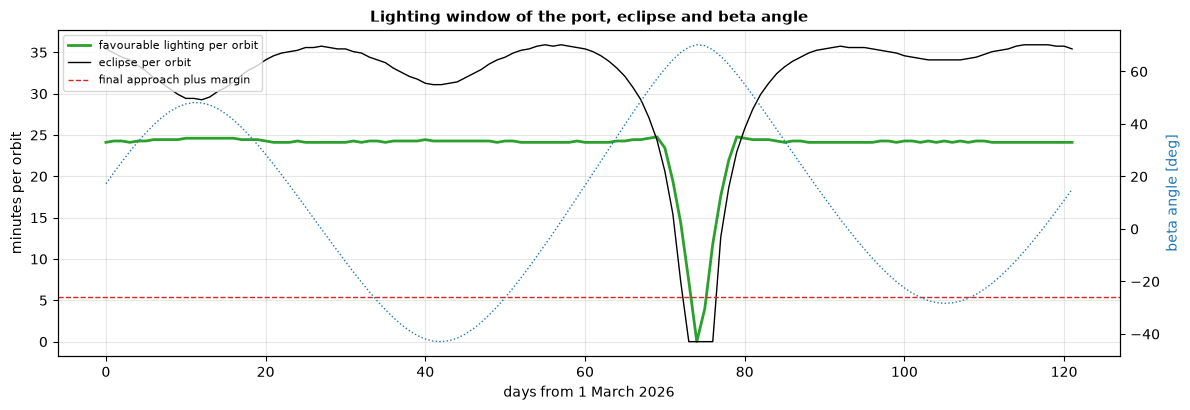

In [6]:
start_date = datetime(2026, 3, 1)
span = np.arange(0, 122)
window_minutes, eclipse_min, beta_day = [], [], []
for day in span:
    jd_day = julian_date_from_datetime(start_date + timedelta(days=int(day)))
    raan_day = RAAN + raan_rate * 86400.0 * (jd_day - epoch)
    daily = port_lighting_timeline(RADIUS, INCLINATION, raan_day, 0.0, jd_day, PERIOD, 10.0,
                                   MU_EARTH, J2_EARTH, R_EARTH, port_normal_lvlh=config.chief.port_axis)
    window_minutes.append(daily.favourable.mean() * PERIOD / 60)
    eclipse_min.append(daily.eclipse.mean() * PERIOD / 60)
    beta_day.append(np.degrees(daily.beta[0]))
window_minutes, eclipse_min, beta_day = map(np.array, (window_minutes, eclipse_min, beta_day))

needed = config.guidance.hold_distances[2] / config.guidance.docking_speed / 60 + 1.0

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(span, window_minutes, color=COL_LIGHT, lw=2, label="favourable lighting per orbit")
ax.plot(span, eclipse_min, color="k", lw=1, label="eclipse per orbit")
ax.axhline(needed, color=COL_NUM, ls="--", lw=1, label="final approach plus margin")
ax.set_xlabel("days from 1 March 2026"); ax.set_ylabel("minutes per orbit")
twin = ax.twinx()
twin.plot(span, beta_day, color=COL_ANA, lw=1, ls=":")
twin.set_ylabel("beta angle [deg]", color=COL_ANA); twin.grid(False)
ax.set_title("Lighting window of the port, eclipse and beta angle")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()

print(f"final approach from S3: {needed - 1.0:.1f} min, {needed:.1f} min with margin")
print(f"favourable window per orbit: from {window_minutes.min():.1f} to {window_minutes.max():.1f} min")
print(f"days with a window shorter than needed: {(window_minutes < needed).sum()} of {len(span)}")
k = np.argmax(window_minutes)
print(f"longest window on day {span[k]} at beta = {beta_day[k]:.1f} deg; "
      f"shortest on day {span[np.argmin(window_minutes)]} at beta = {beta_day[np.argmin(window_minutes)]:.1f} deg")

For most of the period the window is remarkably constant, about 24 minutes, because it is bounded on one side by the incidence limit and on the other by the entry into eclipse, and the two move together. That is more than four times the 5.4 minutes that the final approach needs with its margin.

The exception is the peak of the beta angle around day 74. As the beta angle approaches 70 degrees the eclipse disappears, which might suggest unlimited light. The opposite happens. The Sun is then almost perpendicular to the orbit plane, the normal of the port lies in that plane, and the incidence never falls below the limit of 70 degrees: the Sun grazes the port all orbit long. For two days the port has no favourable window at all, and for about a week around them the window is shorter than usual. A port on the V-bar is best lit at moderate beta angles, and a docking planned around a peak needs another lighting criterion or its own light.

## Waiting for the light

The mission manager of the simulation has a go/no-go before the final approach. With the lighting gate enabled, the deputy stays at the last hold point, 20 m from the port, until the lighting is favourable and will remain so for the whole final approach plus a margin. The two runs below start at that hold point at the same instant, chosen so that the port is not lit when the deputy is ready; one ignores the lighting, the other waits.

lighting ignored   outcome docked; hold at S3   2.0 min for 0.112 m/s; final approach starts at   2.0 min; in eclipse 100 %, port lit   0 % of it
lighting gate      outcome docked; hold at S3  68.3 min for 0.890 m/s; final approach starts at  68.3 min; in eclipse   0 %, port lit  97 % of it


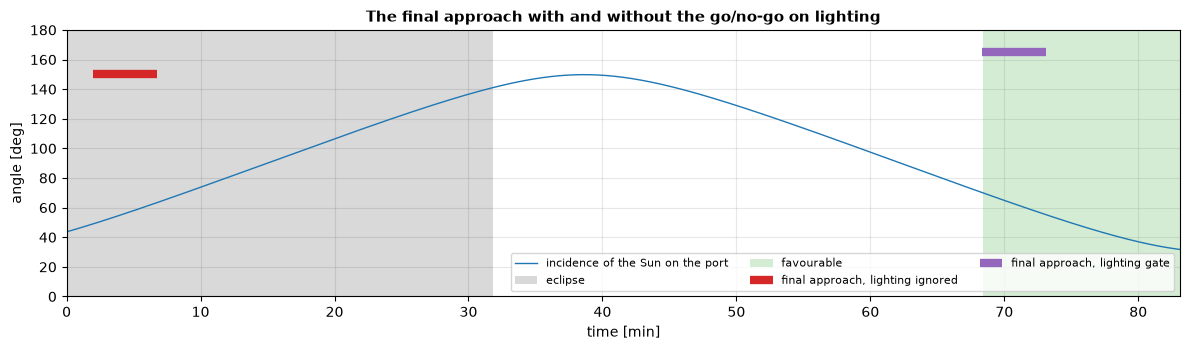

In [7]:
def near_hold(lighting_gate, argument_of_latitude_deg):
    c = SimulationConfig(seed=4)
    c.chief.argument_of_latitude_deg = argument_of_latitude_deg
    c.initial.start_hold = 2
    c.initial.position_offset = np.array([0.05, -0.08, -0.04])
    c.initial.velocity_offset = np.array([0.001, -0.001, 0.001])
    c.initial.attitude_error = np.array([0.002, -0.002, 0.003])
    c.initial.navigation_position_error = np.array([0.03, -0.03, 0.02])
    c.initial.navigation_velocity_error = np.array([0.001, 0.001, -0.001])
    c.navigation.initial_position_std = 0.05
    c.navigation.initial_velocity_std = 0.005
    c.guidance.lighting_gate = lighting_gate
    c.max_duration = 9000.0
    return c

# start the scenario shortly after a favourable window has closed
window_end = timeline.windows()[0][1]
latitude = np.degrees(np.sqrt(MU_EARTH / RADIUS**3) * (window_end + 120.0))

runs = {"lighting ignored": simulate(near_hold(False, latitude)), "lighting gate": simulate(near_hold(True, latitude))}
lighting = port_lighting_timeline(RADIUS, INCLINATION, RAAN, np.deg2rad(latitude), epoch, 9000.0, 5.0,
                                  MU_EARTH, J2_EARTH, R_EARTH, port_normal_lvlh=config.chief.port_axis)

fig, ax = plt.subplots(figsize=(12, 3.6))
m = lighting.t / 60
ax.plot(m, np.degrees(lighting.incidence), color=COL_ANA, lw=1, label="incidence of the Sun on the port")
ax.fill_between(m, 0, 180, where=lighting.eclipse, color="k", alpha=0.15, lw=0, label="eclipse")
ax.fill_between(m, 0, 180, where=lighting.favourable, color=COL_LIGHT, alpha=0.2, lw=0, label="favourable")
for (name, run), level, color in zip(runs.items(), (150, 165), (COL_NUM, COL_ZONE)):
    final = run.phase == Phase.FINAL_APPROACH
    ax.plot(run.t[final] / 60, np.full(final.sum(), level), color=color, lw=6, solid_capstyle="butt",
            label=f"final approach, {name}")
ax.set_ylim(0, 180); ax.set_xlim(0, max(run.duration for run in runs.values()) / 60 + 10)
ax.set_xlabel("time [min]"); ax.set_ylabel("angle [deg]")
ax.set_title("The final approach with and without the go/no-go on lighting")
ax.legend(fontsize=8, ncol=3, loc="lower right")
fig.tight_layout()

for name, run in runs.items():
    final = run.phase == Phase.FINAL_APPROACH
    hold = run.phase == Phase.HOLD_NEAR
    lit = (~run.eclipse[final]) & (run.sun_lvlh[final] @ config.chief.port_axis > np.cos(np.radians(70)))
    spent = run.delta_v_by_phase()
    print(f"{name:18s} outcome {run.outcome}; hold at S3 {hold.sum() / 60:5.1f} min for {spent['hold at S3']:.3f} m/s; "
          f"final approach starts at {run.t[final][0] / 60:5.1f} min; in eclipse {run.eclipse[final].mean() * 100:3.0f} %, "
          f"port lit {lit.mean() * 100:3.0f} % of it")

Both runs dock. The run that ignores the lighting starts its final approach two minutes after the beginning and flies all of it in eclipse: with a real camera it would have had no measurements. The run with the gate waits at S3 for 68 minutes, until the port is lit and will stay lit long enough, and flies the final approach in the light.

The wait is not free. Holding a point 20 m from the port for 68 minutes costs 0.89 m/s, against 0.11 m/s for the nominal two minutes: station keeping at close range, with a tight controller, consumes about 0.8 m/s per hour. The conclusion concerns planning more than control. The lighting windows are known days in advance, so the departure from S2 should be timed for the deputy to reach S3 shortly before a window opens, and the gate at S3 should remain a check, not the place where the waiting is done.

## Summary

`sun_position`, `beta_angle`, `in_eclipse` and `eclipse_fraction_circular` give the position of the Sun, the beta angle and the eclipses, validated against published astronomical events and against a direct count along the orbit. `port_lighting_timeline` turns them into the lighting of a docking port in the frame of the chief and into the windows in which an optical sensor can work, and `beta_angle_history` follows the beta angle over months.

For the reference mission the port is in favourable light for about 24 minutes per orbit, right before the chief enters eclipse, several times what the final approach needs. Two results are less obvious. Around the peaks of the beta angle the port is never well lit although there is no eclipse, because the Sun grazes it all orbit long. And waiting for the light at the last hold point is expensive, so the lighting has to enter the planning of the approach and not only a check at its end.

The analysis uses a cylindrical shadow without penumbra and treats the port as a flat surface with a single normal. It does not model the shadows that the chief casts on itself, the light reflected by the Earth, or the response of a specific camera. The limits of 70 degrees on the incidence and of 30 degrees on the exclusion cone are scenario parameters.